In [ ]:
import numpy as np
import random
import time
from tqdm import tqdm

In [ ]:
from google.colab import drive
import os ###RUN THIS CELL AFTER GENERATING THE EMBEDDINGS
import numpy as np
import pandas as pd

# Mount Drive (if not already mounted)
drive.mount('/content/drive')

# Paths for cleaned data
drive_clean_path = '/content/drive/MyDrive/clean/papers.parquet'
local_clean_path = 'clean/papers.parquet'

os.makedirs('clean', exist_ok=True)

df = None
if os.path.exists(drive_clean_path):
    print('Loaded cleaned dataset from Drive:', drive_clean_path)
    df = pd.read_parquet(drive_clean_path)
elif os.path.exists(local_clean_path):
    print('Loaded cleaned dataset from local folder:', local_clean_path)
    df = pd.read_parquet(local_clean_path)
    # Optionally sync to Drive
    os.makedirs('/content/drive/MyDrive/clean', exist_ok=True)
    df.to_parquet(drive_clean_path)
    print('Saved a copy of cleaned dataset to Drive for future sessions.')
else:
    print('No cleaned dataset found. Run the "Raw data → cleaning" section below once.')
    df = None

# Embedding paths
drive_minilm = '/content/drive/MyDrive/embeddings.npy'
local_minilm = 'clean/embeddings.npy'
# scibert Embedding paths
drive_scibert_10k = "/content/drive/MyDrive/scibert_embeddings_10k.npy"
local_scibert_10k = "clean/scibert_embeddings_10k.npy"
# BERT CLS Embedding paths
drive_bert = '/content/drive/MyDrive/embeddings_bert_10k.npy'
local_bert = 'clean/embeddings_bert_10k.npy'

# WORD2VEC PATHS (NEW)
drive_w2v = '/content/drive/MyDrive/embeddings_w2v.npy'
local_w2v = 'clean/embeddings_w2v.npy'


'''drive_bert = '/content/drive/MyDrive/embeddings_bert.npy'
local_bert = 'clean/embeddings_bert.npy'*//'''#RUN AFTER GENERATING THE EMBEDDINGS use these two methods
def load_embedding(drive_path, local_path, name):
    if os.path.exists(local_path):
        print(f'Loaded {name} embeddings from local file: {local_path}')
        return np.load(local_path)
    if os.path.exists(drive_path):
        print(f'Loaded {name} embeddings from Drive: {drive_path}')
        arr = np.load(drive_path)
        # cache locally
        np.save(local_path, arr)
        print(f' Cached {name} embeddings locally at: {local_path}')
        return arr
    print(f'{name} embeddings not found. Run the "{name} embeddings generation" cell once below.')
    return None

embeddings = load_embedding(drive_minilm, local_minilm, 'MiniLM')
scibert_embeddings_10k = load_embedding(drive_scibert_10k, local_scibert_10k, "SciBERT 10K")
bert_cls_embeddings = load_embedding(drive_bert, local_bert, "BERT CLS 10K")

w2v_embeddings = load_embedding(drive_w2v, local_w2v, 'Word2Vec')


 #RUN AFTER GENERATING THE EMBEDDINGS use these two methods
print('\n Ready to continue analysis (if df and embeddings are loaded successfully).')


Mounted at /content/drive
Loaded cleaned dataset from Drive: /content/drive/MyDrive/clean/papers.parquet
Loaded MiniLM embeddings from Drive: /content/drive/MyDrive/embeddings.npy
 Cached MiniLM embeddings locally at: clean/embeddings.npy
Loaded SciBERT 10K embeddings from Drive: /content/drive/MyDrive/scibert_embeddings_10k.npy
 Cached SciBERT 10K embeddings locally at: clean/scibert_embeddings_10k.npy
BERT CLS 10K embeddings not found. Run the "BERT CLS 10K embeddings generation" cell once below.
Loaded Word2Vec embeddings from Drive: /content/drive/MyDrive/embeddings_w2v.npy
 Cached Word2Vec embeddings locally at: clean/embeddings_w2v.npy

 Ready to continue analysis (if df and embeddings are loaded successfully).


In [ ]:
!pip install kaggle
import os

os.makedirs("data", exist_ok=True)
os.makedirs("clean", exist_ok=True)

In [ ]:
from google.colab import files
files.upload()


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"nusratcs6342","key":"76a7cf82affaf3a4971e238f9344b40c"}'}

In [ ]:
#save downloaded json in drive
from google.colab import drive
drive.mount('/content/drive')

!cp data/arxiv-metadata-oai-snapshot.json "/content/arxiv.zip"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat 'data/arxiv-metadata-oai-snapshot.json': No such file or directory


In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d Cornell-University/arxiv
!unzip arxiv.zip -d data

Dataset URL: https://www.kaggle.com/datasets/Cornell-University/arxiv
License(s): CC0-1.0
 99% 1.51G/1.53G [00:19<00:00, 277MB/s]
100% 1.53G/1.53G [00:19<00:00, 85.5MB/s]
Archive:  arxiv.zip
  inflating: data/arxiv-metadata-oai-snapshot.json  


In [ ]:
import pandas as pd
import json

rows = []
with open("data/arxiv-metadata-oai-snapshot.json", "r") as f:
    for line in f:
        paper = json.loads(line)
        cats = paper["categories"].split()
        #only AI+ML related categories
        if any(c.startswith(("cs.AI", "cs.LG", "cs.CL", "cs.CV", "stat.ML")) for c in cats):
            rows.append({
                "id": paper["id"],
                "title": paper["title"],
                "abstract": paper["abstract"],
                "categories": cats
            })

df = pd.DataFrame(rows)
df.shape

(497807, 4)

In [ ]:
import re
import os

def clean_text(text):
    text = text.replace("\n", " ")
    text = re.sub(r"\$.*?\$", "", text)
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9 .,]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["title_clean"] = df["title"].apply(clean_text)
df["abstract_clean"] = df["abstract"].apply(clean_text)

os.makedirs("clean", exist_ok=True)
clean_path = "clean/papers.parquet"
df.to_parquet(clean_path)
print(" Saved cleaned dataset to", clean_path)

# Also save a copy to Drive if mounted
drive_clean_dir = "/content/drive/MyDrive/clean"
try:
    if os.path.exists("/content/drive"):
        os.makedirs(drive_clean_dir, exist_ok=True)
        drive_clean_path = os.path.join(drive_clean_dir, "papers.parquet")
        df.to_parquet(drive_clean_path)
        print(" Also saved cleaned dataset to Drive at", drive_clean_path)
except Exception as e:
    print(" Could not save to Drive:", e)


 Saved cleaned dataset to clean/papers.parquet
 Also saved cleaned dataset to Drive at /content/drive/MyDrive/clean/papers.parquet


In [ ]:
import os, pandas as pd
clean_path='clean/papers.parquet'
if os.path.exists(clean_path):
    print('Loading cleaned dataset...')
    df=pd.read_parquet(clean_path)
else:
    print('No cleaned file, running cleaning...')


Loading cleaned dataset...


In [ ]:
import os

print("MiniLM exists:", os.path.exists("clean/embeddings.npy"))
print("SciBERT exists:", os.path.exists("clean/scibert_embeddings.npy"))


MiniLM exists: False
SciBERT exists: False


In [ ]:
df.to_json("clean/papers.json", orient="records", lines=True)
df.to_parquet("clean/papers.parquet")

df.head(25)


,id,title,abstract,categories,title_clean,abstract_clean
0,0704.0047,Intelligent location of simultaneously active ...,The intelligent acoustic emission locator is...,"[cs.NE, cs.AI]",Intelligent location of simultaneously active ...,The intelligent acoustic emission locator is d...
1,0704.0050,Intelligent location of simultaneously active ...,Part I describes an intelligent acoustic emi...,"[cs.NE, cs.AI]",Intelligent location of simultaneously active ...,Part I describes an intelligent acoustic emiss...
2,0704.0304,The World as Evolving Information,This paper discusses the benefits of describ...,"[cs.IT, cs.AI, math.IT, q-bio.PE]",The World as Evolving Information,This paper discusses the benefits of describin...
3,0704.0671,Learning from compressed observations,The problem of statistical learning is to co...,"[cs.IT, cs.LG, math.IT]",Learning from compressed observations,The problem of statistical learning is to cons...
4,0704.0954,Sensor Networks with Random Links: Topology De...,"In a sensor network, in practice, the commun...","[cs.IT, cs.LG, math.IT]",Sensor Networks with Random Links Topology Des...,"In a sensor network, in practice, the communic..."
5,0704.0985,Architecture for Pseudo Acausal Evolvable Embe...,Advances in semiconductor technology are con...,"[cs.NE, cs.AI]",Architecture for Pseudo Acausal Evolvable Embe...,Advances in semiconductor technology are contr...
6,0704.1020,The on-line shortest path problem under partia...,The on-line shortest path problem is conside...,"[cs.LG, cs.SC]",The online shortest path problem under partial...,The online shortest path problem is considered...
7,0704.1028,A neural network approach to ordinal regression,Ordinal regression is an important type of l...,"[cs.LG, cs.AI, cs.NE]",A neural network approach to ordinal regression,Ordinal regression is an important type of lea...
8,0704.1139,High-dimensional variable selection,This paper explores the following question: ...,"[math.ST, stat.ML, stat.TH]",Highdimensional variable selection,This paper explores the following question wha...
9,0704.1267,Text Line Segmentation of Historical Documents...,There is a huge amount of historical documen...,[cs.CV],Text Line Segmentation of Historical Documents...,There is a huge amount of historical documents...


In [ ]:
df.head(25)

,id,title,abstract,categories,title_clean,abstract_clean
0,0704.0047,Intelligent location of simultaneously active ...,The intelligent acoustic emission locator is...,"[cs.NE, cs.AI]",Intelligent location of simultaneously active ...,The intelligent acoustic emission locator is d...
1,0704.0050,Intelligent location of simultaneously active ...,Part I describes an intelligent acoustic emi...,"[cs.NE, cs.AI]",Intelligent location of simultaneously active ...,Part I describes an intelligent acoustic emiss...
2,0704.0304,The World as Evolving Information,This paper discusses the benefits of describ...,"[cs.IT, cs.AI, math.IT, q-bio.PE]",The World as Evolving Information,This paper discusses the benefits of describin...
3,0704.0671,Learning from compressed observations,The problem of statistical learning is to co...,"[cs.IT, cs.LG, math.IT]",Learning from compressed observations,The problem of statistical learning is to cons...
4,0704.0954,Sensor Networks with Random Links: Topology De...,"In a sensor network, in practice, the commun...","[cs.IT, cs.LG, math.IT]",Sensor Networks with Random Links Topology Des...,"In a sensor network, in practice, the communic..."
5,0704.0985,Architecture for Pseudo Acausal Evolvable Embe...,Advances in semiconductor technology are con...,"[cs.NE, cs.AI]",Architecture for Pseudo Acausal Evolvable Embe...,Advances in semiconductor technology are contr...
6,0704.1020,The on-line shortest path problem under partia...,The on-line shortest path problem is conside...,"[cs.LG, cs.SC]",The online shortest path problem under partial...,The online shortest path problem is considered...
7,0704.1028,A neural network approach to ordinal regression,Ordinal regression is an important type of l...,"[cs.LG, cs.AI, cs.NE]",A neural network approach to ordinal regression,Ordinal regression is an important type of lea...
8,0704.1139,High-dimensional variable selection,This paper explores the following question: ...,"[math.ST, stat.ML, stat.TH]",Highdimensional variable selection,This paper explores the following question wha...
9,0704.1267,Text Line Segmentation of Historical Documents...,There is a huge amount of historical documen...,[cs.CV],Text Line Segmentation of Historical Documents...,There is a huge amount of historical documents...


In [ ]:
print(df[["title", "title_clean"]].head(3))
print(df[["abstract", "abstract_clean"]].head(1).values[0][0][:400])


                                               title  \
0  Intelligent location of simultaneously active ...   
1  Intelligent location of simultaneously active ...   
2                  The World as Evolving Information   

                                         title_clean  
0  Intelligent location of simultaneously active ...  
1  Intelligent location of simultaneously active ...  
2                  The World as Evolving Information  
  The intelligent acoustic emission locator is described in Part I, while Part
II discusses blind source separation, time delay estimation and location of two
simultaneously active continuous acoustic emission sources.
  The location of acoustic emission on complicated aircraft frame structures is
a difficult problem of non-destructive testing. This article describes an
intelligent acoustic emissi


In [ ]:
df.isna().sum()


,0
id,0
title,0
abstract,0
categories,0
title_clean,0
abstract_clean,0


In [ ]:
import pandas as pd

df = pd.read_parquet("clean/papers.parquet")
df.shape


(497807, 6)

In [ ]:
df["text"] = df["title_clean"] + ". " + df["abstract_clean"]
texts = df["text"].tolist()

len(texts)


497807

SciBERT Embeddings

In [ ]:
# =====SciBERT Embeddings (10K only) =====
# HuggingFace model + manual pooling (correct method)

from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np
import os

if df is None:
    raise ValueError("Dataframe df is not loaded.")

# Load real SciBERT
tokenizer = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")
model = AutoModel.from_pretrained("allenai/scibert_scivocab_uncased")
model.eval()

# ---- LIMIT TO FIRST 10,000 ----
texts = df["abstract_clean"].tolist()[:10000]
print(f"Generating SciBERT embeddings for {len(texts)} samples...")

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * mask, dim=1) / torch.clamp(mask.sum(dim=1), min=1e-9)

batch_size = 8
embeds = []

for i in range(0, len(texts), batch_size):
    batch = texts[i:i+batch_size]

    encoded = tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )

    with torch.no_grad():
        output = model(**encoded)

    pooled = mean_pooling(output, encoded["attention_mask"])
    embeds.append(pooled.cpu().numpy())

    print(f"Processed {i + len(batch)} / {len(texts)}")

scibert_embeddings = np.vstack(embeds)

# ---- Save locally ----
os.makedirs("clean", exist_ok=True)
local_scibert = "clean/scibert_embeddings_10k.npy"
np.save(local_scibert, scibert_embeddings)
print(" Saved SciBERT embeddings locally:", local_scibert)

# ---- Save to Drive ----
drive_scibert = "/content/drive/MyDrive/scibert_embeddings_10k.npy"
try:
    np.save(drive_scibert, scibert_embeddings)
    print(" Also saved to Drive:", drive_scibert)
except Exception as e:
    print(" Could not save to Drive:", e)

print("\n SciBERT embeddings READY (10K subset).")


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/442M [00:00<?, ?B/s]

Generating SciBERT embeddings for 10000 samples...
Processed 8 / 10000
Processed 16 / 10000
Processed 24 / 10000
Processed 32 / 10000
Processed 40 / 10000
Processed 48 / 10000
Processed 56 / 10000
Processed 64 / 10000
Processed 72 / 10000
Processed 80 / 10000
Processed 88 / 10000
Processed 96 / 10000
Processed 104 / 10000
Processed 112 / 10000
Processed 120 / 10000
Processed 128 / 10000
Processed 136 / 10000
Processed 144 / 10000
Processed 152 / 10000
Processed 160 / 10000
Processed 168 / 10000
Processed 176 / 10000
Processed 184 / 10000
Processed 192 / 10000
Processed 200 / 10000
Processed 208 / 10000
Processed 216 / 10000
Processed 224 / 10000
Processed 232 / 10000
Processed 240 / 10000
Processed 248 / 10000
Processed 256 / 10000
Processed 264 / 10000
Processed 272 / 10000
Processed 280 / 10000
Processed 288 / 10000
Processed 296 / 10000
Processed 304 / 10000
Processed 312 / 10000
Processed 320 / 10000
Processed 328 / 10000
Processed 336 / 10000
Processed 344 / 10000
Processed 352 / 

In [ ]:
scibert_embeddings.shape


(10000, 768)

*  (Sentence-BERT) embeddings generation*

In [ ]:
#  (Sentence-BERT) embeddings generation, run ONCE if needed, when you dont have the embeddings saved
from sentence_transformers import SentenceTransformer
import numpy as np
import os

if df is None:
    raise ValueError("Dataframe df is not loaded. Run the START HERE cell and/or cleaning first.")

model_minilm = SentenceTransformer("all-MiniLM-L6-v2")
texts = df["abstract_clean"].tolist()

print("Generating MiniLM embeddings")
embeddings = model_minilm.encode(
    texts,
    batch_size=64,
    show_progress_bar=True
)

os.makedirs("clean", exist_ok=True)
local_minilm = "clean/embeddings.npy"
np.save(local_minilm, embeddings)
print("Saved MiniLM embeddings locally to", local_minilm)

# Save to Drive
drive_minilm = "/content/drive/MyDrive/embeddings.npy"
try:
    if os.path.exists("/content/drive"):
        np.save(drive_minilm, embeddings)
        print("Also saved MiniLM embeddings to Drive at", drive_minilm)
except Exception as e:
    print("Could not save MiniLM embeddings to Drive:", e)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generating MiniLM embeddings


Batches:   0%|          | 0/7779 [00:00<?, ?it/s]

Saved MiniLM embeddings locally to clean/embeddings.npy
Also saved MiniLM embeddings to Drive at /content/drive/MyDrive/embeddings.npy


In [ ]:
embeddings.shape

(497807, 384)

Word2Vec-- add your word2vec embedding generation here

In [ ]:
!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 39.6 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec


In [ ]:
# Word2Vec embeddings generation (run once if needed)

from gensim.models import Word2Vec
import nltk
import numpy as np
import os

# Fix punkt_tab error
nltk.download('punkt')
nltk.download('punkt_tab')

# Ensure df is loaded
if df is None:
    raise ValueError("Dataframe df is not loaded. Run START HERE or cleaning first.")

# Paths
local_w2v = "clean/embeddings_w2v.npy"
drive_w2v = "/content/drive/MyDrive/embeddings_w2v.npy"

# ---------------- AUTO LOAD IF EXISTS ----------------
if os.path.exists(local_w2v):
    print(" Loaded Word2Vec embeddings from local file:", local_w2v)
    w2v_embeddings = np.load(local_w2v)

elif os.path.exists(drive_w2v):
    print(" Loaded Word2Vec embeddings from Drive:", drive_w2v)
    w2v_embeddings = np.load(drive_w2v)
    os.makedirs("clean", exist_ok=True)
    np.save(local_w2v, w2v_embeddings)
    print("Cached locally:", local_w2v)

else:
    # ---------------- GENERATE WORD2VEC ----------------
    print(" Generating Word2Vec embeddings...")

    texts = df["abstract_clean"].tolist()
    tokenized = [nltk.word_tokenize(t.lower()) for t in texts]

    # Train Word2Vec
    w2v_model = Word2Vec(
        sentences=tokenized,
        vector_size=300,
        window=5,
        min_count=2,
        sg=1,   # skip-gram = better quality
        workers=4
    )

    # Convert each document → average of its word vectors
    w2v_embeddings = np.array([
        np.mean([w2v_model.wv[word] for word in tokens if word in w2v_model.wv]
                or [np.zeros(300)], axis=0)
        for tokens in tokenized
    ])

    # Save locally
    os.makedirs("clean", exist_ok=True)
    np.save(local_w2v, w2v_embeddings)
    print(" Saved Word2Vec embeddings locally:", local_w2v)

    # Save to Drive
    try:
        if os.path.exists("/content/drive/MyDrive"):
            np.save(drive_w2v, w2v_embeddings)
            print(" Also saved Word2Vec embeddings to Drive:", drive_w2v)
        else:
            print(" Drive not mounted — only local save completed.")
    except Exception as e:
        print(" Could not save Word2Vec to Drive:", e)

print("\n Word2Vec embeddings ready for analysis!")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


🔄 Generating Word2Vec embeddings...
✅ Saved Word2Vec embeddings locally: clean/embeddings_w2v.npy
 Also saved Word2Vec embeddings to Drive: /content/drive/MyDrive/embeddings_w2v.npy

 Word2Vec embeddings ready for analysis!


In [ ]:
print("Word2Vec embeddings shape:", w2v_embeddings.shape)

Word2Vec embeddings shape: (497807, 300)


In [ ]:
print("DF shape:", df.shape)
print("MiniLM embeddings shape:", embeddings.shape)


DF shape: (497807, 7)
MiniLM embeddings shape: (497807, 384)


In [ ]:
##HNSW--search engine

In [ ]:
!pip install hnswlib


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp312-cp312-linux_x86_64.whl size=2527728 sha256=3ea484777aacb5e272d27b36d6e06b64c07a47ee7efdc8088eb75f9567798f41
  Stored in directory: /root/.cache/pip/wheels/ac/39/b3/cbd7f9cbb76501d2d5fbc84956e70d0b94e788aac87bda465e
Successfully built hnswlib


In [ ]:
import hnswlib

In [ ]:
def build_index_fast(emb):
    dim = emb.shape[1]
    num = emb.shape[0]

    index = hnswlib.Index(space='cosine', dim=dim)
    index.init_index(
        max_elements=num,
        ef_construction=80,  # lower → faster
        M=8                 # lower → faster
    )
    index.add_items(emb, np.arange(num))
    index.set_ef(30)
    return index


HNSW

In [ ]:
index_minilm = build_index_fast(embeddings)
print("MiniLM HNSW index built successfully!")


MiniLM HNSW index built successfully!


In [ ]:
# ---- SAVE MiniLM index to Drive ----
minilm_index_path = "/content/drive/MyDrive/index_minilm.bin"
index_minilm.save_index(minilm_index_path)
print("Saved MiniLM index:", minilm_index_path)


Saved MiniLM index: /content/drive/MyDrive/index_minilm.bin


In [ ]:
print("Building SciBERT HNSW index...")

index_scibert = build_index_fast(scibert_embeddings_10k)
print("SciBERT index built!")


Building SciBERT HNSW index...
SciBERT index built!


In [ ]:
index_scibert.save_index("/content/drive/MyDrive/index_scibert_10k.bin")
print("Saved: index_scibert_10k.bin")


Saved: index_scibert_10k.bin


In [ ]:
print("Building Word2Vec HNSW index...")

index_w2v = build_index_fast(w2v_embeddings)
print("Word2Vec index built!")


Building Word2Vec HNSW index...
Word2Vec index built!


In [ ]:
index_w2v.save_index("/content/drive/MyDrive/index_w2v.bin")
print("Saved: index_w2v.bin")


Saved: index_w2v.bin


In [ ]:
!find /content/drive/MyDrive -iname "*w2v*" -type f


/content/drive/MyDrive/embeddings_w2v.npy
/content/drive/MyDrive/index_w2v.bin


In [ ]:
!ls /content/drive/MyDrive | grep index


index_minilm.bin
index_minilm_v1.bin
index_scibert_10k.bin
index_w2v.bin


In [ ]:
def load_hnsw_index(path, dim):
    index = hnswlib.Index(space='cosine', dim=dim)
    index.load_index(path)
    index.set_ef(30)
    return index
index_minilm = load_hnsw_index("/content/drive/MyDrive/index_minilm.bin", 384)
index_scibert = load_hnsw_index("/content/drive/MyDrive/index_scibert_10k.bin", 768)
index_w2v = load_hnsw_index("/content/drive/MyDrive/index_w2v.bin", 300)




In [ ]:
from sentence_transformers import SentenceTransformer

model_minilm = SentenceTransformer("all-MiniLM-L6-v2")
print("MiniLM model loaded")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

MiniLM model loaded


In [ ]:
from transformers import AutoModel, AutoTokenizer


In [ ]:
# models
model_minilm = SentenceTransformer("all-MiniLM-L6-v2")
model_scibert = AutoModel.from_pretrained("allenai/scibert_scivocab_uncased")
tokenizer_scibert = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")

# indexes
index_minilm  = load_hnsw_index("/content/drive/MyDrive/index_minilm.bin", 384)
index_scibert = load_hnsw_index("/content/drive/MyDrive/index_scibert_10k.bin", 768)
index_w2v     = load_hnsw_index("/content/drive/MyDrive/index_w2v.bin", 300)

# embeddings
embeddings_minilm  = load_embedding(drive_minilm, local_minilm, "MiniLM")
embeddings_scibert = load_embedding(drive_scibert_10k, local_scibert_10k, "SciBERT")
embeddings_w2v     = load_embedding(drive_w2v, local_w2v, "Word2Vec")


Loaded MiniLM embeddings from local file: clean/embeddings.npy
Loaded SciBERT embeddings from local file: clean/scibert_embeddings_10k.npy
Loaded Word2Vec embeddings from local file: clean/embeddings_w2v.npy


In [ ]:
import torch

def embed_scibert(text):
    encoded = tokenizer_scibert(
        [text],
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )
    with torch.no_grad():
        output = model_scibert(**encoded)

    mask = encoded["attention_mask"].unsqueeze(-1).expand(output.last_hidden_state.size()).float()
    pooled = torch.sum(output.last_hidden_state * mask, dim=1) / torch.clamp(mask.sum(dim=1), min=1e-9)
    return pooled.cpu().numpy().astype("float32")


In [ ]:
def search_papers(query, top_k, model_choice):

    # Select model + index + dataframe slice
    if model_choice == "MiniLM":
        q_emb = model_minilm.encode([query]).astype("float32")
        idx = index_minilm
        source_df = df

    elif model_choice == "SciBERT (10K subset)":
        q_emb = embed_scibert(query)
        idx = index_scibert
        source_df = df.iloc[:10000]

    else:
        return "❌ Invalid model selection."

    # Run HNSW search
    labels, distances = idx.knn_query(q_emb, k=top_k)

    results = []
    for rank, row_index in enumerate(labels[0], start=1):

        row = source_df.iloc[row_index]

        # ---- Fix link ----
        paper_id = str(row["id"])
        url = f"https://arxiv.org/abs/{paper_id}"

        # ---- Fix categories ----
        cats = row["categories"]
        if isinstance(cats, list):
            cats = ", ".join(cats)
        else:
            cats = str(cats)

        # ---- Fix abstract formatting ----
        abs_clean = row["abstract"].replace("\n", " ").strip()
        abs_clean = abs_clean[:500]

        # ---- Final formatted card ----
        card = (
            f"### {rank}. [{row['title']}]({url})\n\n"
            f"**Categories:** {cats}\n\n"
            f"**Abstract:** {abs_clean}...\n\n"
            f"🔗 **Link:** [{url}]({url})"
        )

        results.append(card)

    return "\n\n---\n\n".join(results)


In [ ]:
import gradio as gr

with gr.Blocks(title="AI Research Paper Search Engine") as demo:

    gr.Markdown("## Intelligent Paper Detective")
    gr.Markdown("Semantic search over scientific papers using MiniLM and SciBERT embeddings + HNSW ANN.")


    model_choice = gr.Dropdown(
        ["MiniLM", "SciBERT (10K subset)"],
        value="MiniLM",
        label="Choose Embedding Model"
    )

    query = gr.Textbox(label="Enter your research topic")
    top_k = gr.Slider(1, 20, value=5, step=1, label="Top K Results")

    output = gr.Markdown()

    search_button = gr.Button("Search")

    search_button.click(
        search_papers,
        inputs=[query, top_k, model_choice],
        outputs=[output]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f283ee44c7374050ba.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**Recall@**

In [ ]:
index_path = "/content/drive/MyDrive/index_minilm_v1.bin"
index_minilm.save_index(index_path)
print("MiniLM index saved to:", index_path)


MiniLM index saved to: /content/drive/MyDrive/index_minilm_v1.bin


In [ ]:
index_minilm = hnswlib.Index(space='cosine', dim=embeddings.shape[1])
index_minilm.load_index("/content/drive/MyDrive/index_minilm_v1.bin")
index_minilm.set_ef(50)
print(" MiniLM index loaded instantly.")


 MiniLM index loaded instantly.


In [ ]:
import random
from tqdm import tqdm
import numpy as np

def evaluate_recall_mrr(df, embeddings, index, embed_fn,
                         sample_size=300, k_list=[5, 10]):
    """
    df: dataframe
    embeddings: np array (N x D)
    index: HNSW index
    embed_fn: function that turns text → embedding (MiniLM or SciBERT)
    sample_size: how many samples to evaluate
    k_list: recall@k values
    """

    N = len(df)
    assert embeddings.shape[0] == N, "DF and embedding count mismatch"

    indices = random.sample(range(N), min(sample_size, N))

    recall = {k: 0 for k in k_list}
    mrr_sum = 0
    total = len(indices)

    for idx in tqdm(indices, desc="Evaluating Recall/MRR"):
        query = df.iloc[idx]["abstract_clean"]   # clean input
        q_emb = embed_fn(query)

        # HNSW search
        labels, _ = index.knn_query(q_emb, k=max(k_list))
        retrieved = labels[0]

        # find where the true item appears in retrieval list
        if idx in retrieved:
            rank = np.where(retrieved == idx)[0][0] + 1   # 1-based
        else:
            rank = None

        # recall@k
        for k in k_list:
            if rank is not None and rank <= k:
                recall[k] += 1

        # mrr
        if rank is not None:
            mrr_sum += 1.0 / rank

    # normalize
    for k in k_list:
        recall[k] = recall[k] / total

    mrr = mrr_sum / total

    return recall, mrr


In [ ]:
def embed_minilm(text):
    return model_minilm.encode([text]).astype("float32")


In [ ]:
def embed_scibert_eval(text):
    return embed_scibert(text)   # you already wrote this


In [ ]:
rec_minilm, mrr_minilm = evaluate_recall_mrr(
    df=df,
    embeddings=embeddings_minilm,
    index=index_minilm,
    embed_fn=embed_minilm,
    sample_size=300,
    k_list=[5, 10]
)


Evaluating Recall/MRR: 100%|██████████| 300/300 [00:03<00:00, 98.28it/s] 


In [ ]:
sub_df = df.iloc[:10000]

rec_scibert, mrr_scibert = evaluate_recall_mrr(
    df=sub_df,
    embeddings=embeddings_scibert,
    index=index_scibert,
    embed_fn=embed_scibert_eval,
    sample_size=300,
    k_list=[5, 10]
)


Evaluating Recall/MRR: 100%|██████████| 300/300 [02:15<00:00,  2.22it/s]


In [ ]:
recall, mrr = evaluate_recall_mrr(
    df=df,
    embeddings=embeddings,
    index=index_minilm,
    model=model_minilm,
    sample_size=500,
    k_list=[5, 10]
)

print("\n===== Recall Results =====")
for k, v in recall.items():
    print(f"Recall@{k}: {v:.4f}")

print(f"\nMRR@10: {mrr:.4f}")


TypeError: evaluate_recall_mrr() got an unexpected keyword argument 'model'

In [ ]:
def evaluate_w2v(df, embeddings, index, sample_size=300, k_list=[5,10]):

    N = len(df)
    indices = random.sample(range(N), min(sample_size, N))

    recall = {k: 0 for k in k_list}
    mrr_sum = 0

    for idx in tqdm(indices, desc="Evaluating Word2Vec"):
        q_emb = embeddings[idx].reshape(1,-1).astype("float32")

        labels, _ = index.knn_query(q_emb, k=max(k_list))

        retrieved = labels[0]

        # position of true index
        if idx in retrieved:
            rank = list(retrieved).index(idx) + 1
        else:
            rank = None

        # Recall
        for k in k_list:
            if rank is not None and rank <= k:
                recall[k] += 1

        # MRR
        if rank is not None:
            mrr_sum += 1.0 / rank

    # normalize
    for k in k_list:
        recall[k] /= len(indices)

    mrr = mrr_sum / len(indices)

    return recall, mrr


In [ ]:
rec_w2v, mrr_w2v = evaluate_w2v(
    df=df,
    embeddings=embeddings_w2v,
    index=index_w2v,
    sample_size=300,
    k_list=[5,10]
)


Evaluating Word2Vec: 100%|██████████| 300/300 [00:00<00:00, 3694.86it/s]


In [ ]:
import pandas as pd

comparison_df = pd.DataFrame([
    ["MiniLM",         384, rec_minilm[5], rec_minilm[10], mrr_minilm],
    ["SciBERT 10K",    768, rec_scibert[5], rec_scibert[10], mrr_scibert],
    ["Word2Vec",       300, rec_w2v[5], rec_w2v[10], mrr_w2v]
    # Add below only if you evaluated PCA:
    # ["SciBERT PCA",  128, rec_pca[5], rec_pca[10], mrr_pca]
], columns=["Model", "Dim", "Recall@5", "Recall@10", "MRR"])

comparison_df


,Model,Dim,Recall@5,Recall@10,MRR
0,MiniLM,384,0.990000,0.990000,0.990000
1,SciBERT 10K,768,0.963333,0.963333,0.963333
2,Word2Vec,300,0.936667,0.936667,0.935000


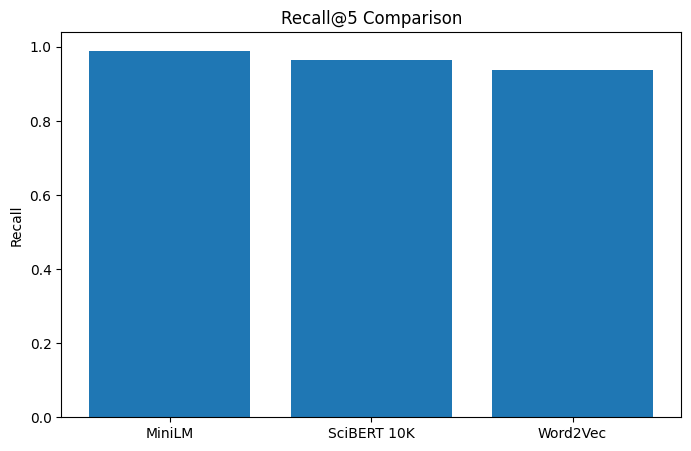

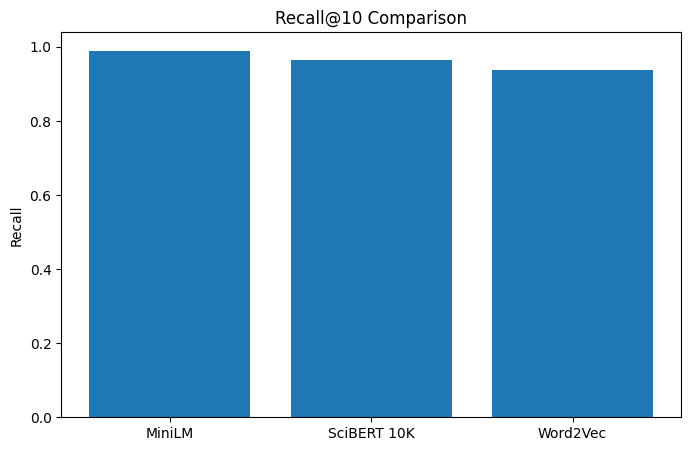

In [ ]:
import matplotlib.pyplot as plt

models = ["MiniLM", "SciBERT 10K", "Word2Vec"]
recall5 = [rec_minilm[5], rec_scibert[5], rec_w2v[5]]
recall10 = [rec_minilm[10], rec_scibert[10], rec_w2v[10]]

plt.figure(figsize=(8,5))
plt.bar(models, recall5)
plt.title("Recall@5 Comparison")
plt.ylabel("Recall")
plt.show()

plt.figure(figsize=(8,5))
plt.bar(models, recall10)
plt.title("Recall@10 Comparison")
plt.ylabel("Recall")
plt.show()


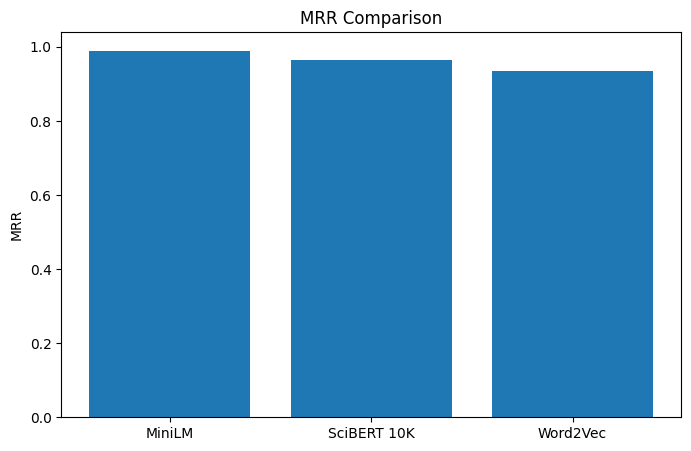

In [ ]:
mrr_values = [mrr_minilm, mrr_scibert, mrr_w2v]

plt.figure(figsize=(8,5))
plt.bar(models, mrr_values)
plt.title("MRR Comparison")
plt.ylabel("MRR")
plt.show()


LAtency

In [ ]:
import time
import numpy as np

def evaluate_latency(index, embeddings, num_queries=200, k=10):
    """
    Measures average query time for HNSW index using precomputed embeddings.
    """
    N = len(embeddings)
    sample_ids = np.random.choice(N, size=min(num_queries, N), replace=False)

    times = []
    for idx in sample_ids:
        q_emb = embeddings[idx].reshape(1, -1).astype("float32")
        start = time.time()
        index.knn_query(q_emb, k=k)
        times.append(time.time() - start)

    return np.mean(times), np.std(times)


In [ ]:
lat_minilm_mean, lat_minilm_std = evaluate_latency(index_minilm, embeddings_minilm)
lat_scibert_mean, lat_scibert_std = evaluate_latency(index_scibert, embeddings_scibert)
lat_w2v_mean, lat_w2v_std = evaluate_latency(index_w2v, embeddings_w2v)


In [ ]:
latency_df = pd.DataFrame([
    ["MiniLM",         384, lat_minilm_mean,  lat_minilm_std],
    ["SciBERT 10K",    768, lat_scibert_mean, lat_scibert_std],
    ["Word2Vec",       300, lat_w2v_mean,     lat_w2v_std],

], columns=["Model", "Dim", "Latency_mean", "Latency_std"])

latency_df


,Model,Dim,Latency_mean,Latency_std
0,MiniLM,384,0.000331,0.000083
1,SciBERT 10K,768,0.000100,0.000036
2,Word2Vec,300,0.000186,0.000038


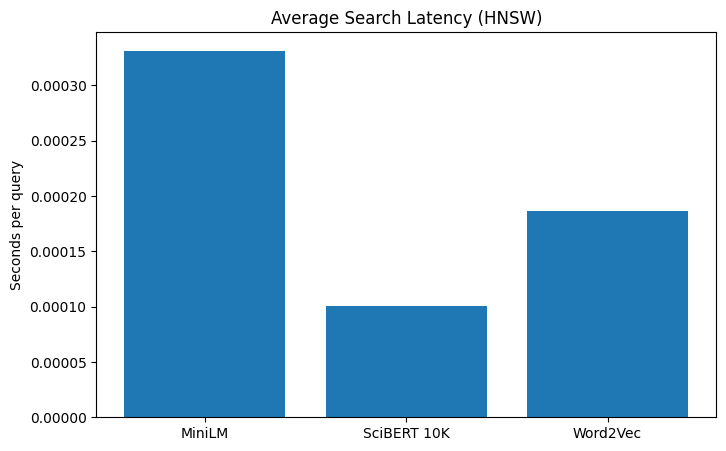

In [ ]:
import matplotlib.pyplot as plt

models = ["MiniLM", "SciBERT 10K", "Word2Vec"]
latencies = [lat_minilm_mean, lat_scibert_mean, lat_w2v_mean]

plt.figure(figsize=(8,5))
plt.bar(models, latencies)
plt.title("Average Search Latency (HNSW)")
plt.ylabel("Seconds per query")
plt.show()


In [ ]:
final_df = pd.DataFrame([
    ["MiniLM", 384, rec_minilm[5], rec_minilm[10], mrr_minilm, lat_minilm_mean],
    ["SciBERT 10K", 768, rec_scibert[5], rec_scibert[10], mrr_scibert, lat_scibert_mean],
    ["Word2Vec", 300, rec_w2v[5], rec_w2v[10], mrr_w2v, lat_w2v_mean],
], columns=["Model", "Dim", "Recall@5", "Recall@10", "MRR", "Latency"])

final_df


,Model,Dim,Recall@5,Recall@10,MRR,Latency
0,MiniLM,384,0.990000,0.990000,0.990000,0.000331
1,SciBERT 10K,768,0.963333,0.963333,0.963333,0.000100
2,Word2Vec,300,0.936667,0.936667,0.935000,0.000186


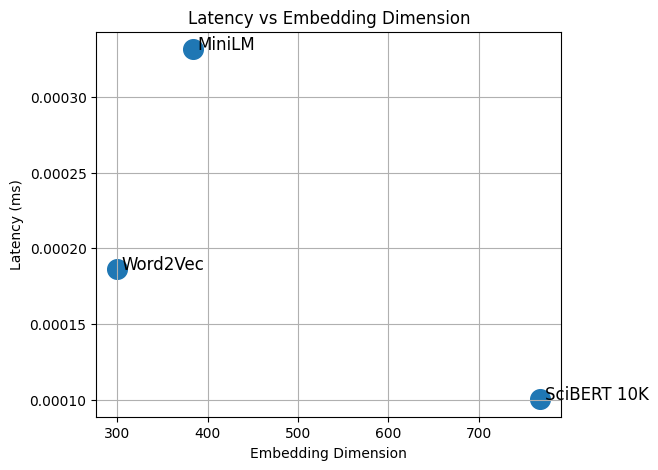

In [ ]:
import matplotlib.pyplot as plt

dims = [384, 768, 300]
lat_means = [lat_minilm_mean, lat_scibert_mean, lat_w2v_mean]
labels = ["MiniLM", "SciBERT 10K", "Word2Vec"]

plt.figure(figsize=(6,5))
plt.scatter(dims, lat_means, s=200)

for i in range(len(dims)):
    plt.text(dims[i]+5, lat_means[i], labels[i], fontsize=12)

plt.xlabel("Embedding Dimension")
plt.ylabel("Latency (ms)")
plt.title("Latency vs Embedding Dimension")
plt.grid(True)
plt.show()


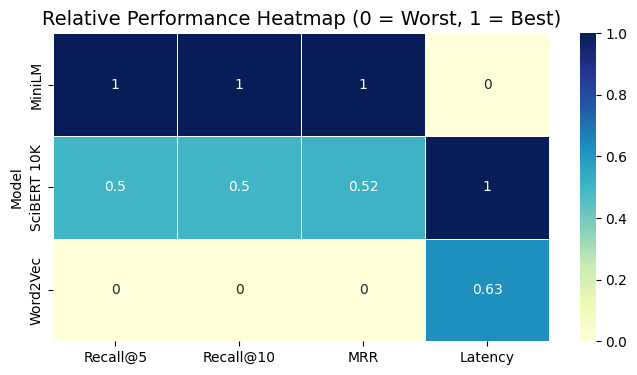

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select columns to compare
metrics = ["Recall@5", "Recall@10", "MRR", "Latency"]

# Normalize each column (0 = worst, 1 = best)
df_norm = final_df.copy()
for m in metrics:
    if m == "Latency":
        # For latency lower = better → invert values
        df_norm[m] = 1 - (final_df[m] - final_df[m].min()) / (final_df[m].max() - final_df[m].min())
    else:
        # Higher = better
        df_norm[m] = (final_df[m] - final_df[m].min()) / (final_df[m].max() - final_df[m].min())

plt.figure(figsize=(8,4))
sns.heatmap(
    df_norm.set_index("Model")[metrics],
    annot=True,
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Relative Performance Heatmap (0 = Worst, 1 = Best)", fontsize=14)
plt.show()
